# 07 · Model tournament (Stage 3)

**Primary convention: B (start of week).** The forecast is issued on the Monday that labels week *t*, so week *t*
is not yet observed: weather and cases are usable up to week *t − 1*. Evidence: the monsoon regime flips at ISO week 40
(month of the week's midpoint), consistent with week-start labels (`reports/features/tables/date_convention_evidence.csv`).
Convention A (end of week, as in Stages 1–2) is reported as a **separate** leaderboard; C (A + one-week case delay) is a
sensitivity check. Rows from different conventions are never ranked together.

**Out-of-time design.** For every season *s* in 2018–2024 each model is trained on labels reported by 31 Dec *s − 1* and
predicts season *s* (origin and target inside *s*). Outer seasons: **2019–2024** (2019–2021 = additional robustness folds;
2022–2024 = the Stage 1/2 benchmark). Anything learned for outer year *Y* — ensemble weights, interval calibration, peak
corrections, alert thresholds — uses only seasons < *Y*. Optuna tunes on 2019–2021 only, so tuned models are reported on
2022–2024 only. **2025 is never loaded** (`load_development_panel`; `season_fold(2025)` raises).

**Features (frozen):** F3 (38) and F8 (24) from Stage 2, with `rain_est="clim"`. **Point forecast:** the distributional
median (MAE-optimal); the conditional mean is reported separately (resource planning, RMSE). Differences below 0.05 MAE
are treated as tentative.

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=FutureWarning)
import numpy as np, pandas as pd
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
np.random.seed(2026)
import matplotlib.pyplot as plt
from cycler import cycler
import optuna
from dengueshield.data import load_development_panel
from dengueshield.models import seasons as S, tournament as T
from dengueshield.models.ensemble import nested_blend

OUT = ROOT / "reports/model_tournament"; FIG = OUT / "figures"
for d in (OUT, FIG): d.mkdir(parents=True, exist_ok=True)
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, INK2, GRID, SURF, MUTED = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb", "#b9b8b2"
plt.rcParams.update({"figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF, "axes.edgecolor": INK2,
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "lines.linewidth": 2, "font.size": 9.5, "axes.titlesize": 10.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False, "axes.prop_cycle": cycler(color=SERIES), "savefig.dpi": 130, "savefig.bbox": "tight"})
def save(fig, name):
    fig.savefig(FIG / f"{name}.png"); plt.show(); plt.close(fig)

panel = load_development_panel(); assert panel.date.dt.year.max() == 2024
FS = S.feature_sets(panel)
print({k: len(v) for k, v in FS.items()}, "| seasons", S.SEASONS, "| outer", S.OUTER, "| tune", S.TUNE)

/Volumes/ssd(mac)2/EDU_HACKATHON/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'F3': 38, 'F8': 24} | seasons (2018, 2019, 2020, 2021, 2022, 2023, 2024) | outer (2019, 2020, 2021, 2022, 2023, 2024) | tune (2019, 2020, 2021)


## 1. Screening: 11 model families × F3/F8 × conventions B and A × 7 seasons × 3 horizons (cached)

In [2]:
import time
t0 = time.time()
screen = T.run_grid(panel, T.SCREEN_MODELS, FS, convs=("B", "A"))
conv_c = T.run_grid(panel, ["glm_poisson", "glm_tweedie", "lgbm_poisson", "xgb_poisson", "cat_poisson"], {"F3": FS["F3"]}, convs=("C",))
preds = pd.concat([screen, conv_c], ignore_index=True)
assert preds.year.max() <= 2024
scores = S.score_table(preds)
fits = preds.groupby(["model", "fs", "conv", "tag", "year", "horizon"]).fit_s.first()
print(f"{len(scores):,} model x season x horizon cells; {len(fits):,} fits; fit time {fits.sum() / 60:.1f} min; loaded in {time.time() - t0:.0f}s")

1,029 model x season x horizon cells; 1,029 fits; fit time 6.2 min; loaded in 10s


In [3]:
def board(sc, conv, years, fs=None):
    s = sc[(sc.conv == conv) & ((sc.fs == fs) if fs else True)]
    return T.leaderboard(s, years)
cols = ["model", "fs", "mae_h2", "mae_h3", "mae_h4", "mae_avg", "year_sd", "rmse", "mae_mean", "rmse_mean", "high_mae", "high_bias", "high_under", "recall", "precision", "false_alert_rate", "fit_s"]
lbB_outer, lbB_bench = board(scores, "B", S.OUTER), board(scores, "B", S.BENCH)
lbA_outer, lbA_bench = board(scores, "A", S.OUTER), board(scores, "A", S.BENCH)
for name, lb in {"B_outer_2019_2024": lbB_outer, "B_bench_2022_2024": lbB_bench, "A_outer_2019_2024": lbA_outer, "A_bench_2022_2024": lbA_bench}.items():
    lb.to_csv(OUT / f"leaderboard_screen_{name}.csv", index=False)
print("CONVENTION B (primary), outer seasons 2019-2024"); display(lbB_outer[cols].round(3))

CONVENTION B (primary), outer seasons 2019-2024


,model,fs,mae_h2,mae_h3,mae_h4,mae_avg,year_sd,rmse,mae_mean,rmse_mean,high_mae,high_bias,high_under,recall,precision,false_alert_rate,fit_s
9,glm_spline,F8,1.119,1.360,1.506,1.328,0.180,2.620,1.381,2.607,4.475,-3.530,0.769,0.559,0.635,0.040,0.492
8,glm_spline,F3,1.123,1.377,1.502,1.334,0.189,2.627,1.395,2.613,4.593,-3.760,0.793,0.529,0.640,0.037,0.579
10,glm_tweedie,F3,1.102,1.325,1.575,1.334,0.235,2.667,1.383,2.622,5.002,-4.214,0.820,0.459,0.644,0.028,0.211
7,glm_poisson_nbdisp,F8,1.112,1.377,1.571,1.353,0.194,2.681,1.426,2.680,4.641,-3.678,0.775,0.534,0.646,0.038,0.251
6,glm_poisson_nbdisp,F3,1.112,1.372,1.588,1.357,0.223,2.685,1.440,2.662,4.869,-4.058,0.809,0.480,0.658,0.033,0.356
4,glm_poisson,F3,1.111,1.385,1.594,1.363,0.186,2.671,1.440,2.662,4.581,-3.549,0.771,0.546,0.640,0.040,0.394
5,glm_poisson,F8,1.113,1.390,1.593,1.365,0.167,2.687,1.426,2.680,4.425,-3.211,0.739,0.581,0.626,0.045,0.258
15,lgbm_l1,F8,1.177,1.413,1.527,1.372,0.239,2.758,NaN,NaN,5.247,-5.107,0.912,0.372,0.666,0.024,0.300
14,lgbm_l1,F3,1.186,1.411,1.523,1.374,0.246,2.763,NaN,NaN,5.276,-5.184,0.928,0.369,0.674,0.022,0.296
13,hurdle_lgbm,F8,1.123,1.426,1.579,1.376,0.154,2.746,1.410,2.731,4.557,-3.543,0.758,0.566,0.602,0.047,0.521


In [4]:
print("CONVENTION B, benchmark seasons 2022-2024"); display(lbB_bench[cols].round(3))

CONVENTION B, benchmark seasons 2022-2024


,model,fs,mae_h2,mae_h3,mae_h4,mae_avg,year_sd,rmse,mae_mean,rmse_mean,high_mae,high_bias,high_under,recall,precision,false_alert_rate,fit_s
2,glm_nb,F3,1.095,1.385,1.486,1.322,0.217,2.654,1.365,2.626,4.780,-3.930,0.800,0.532,0.694,0.032,0.442
3,glm_nb,F8,1.098,1.378,1.494,1.323,0.199,2.663,1.373,2.650,4.675,-3.599,0.767,0.566,0.683,0.036,0.281
8,glm_spline,F3,1.113,1.409,1.486,1.336,0.190,2.653,1.392,2.633,4.634,-3.697,0.781,0.563,0.691,0.035,0.633
7,glm_poisson_nbdisp,F8,1.109,1.394,1.508,1.337,0.204,2.684,1.401,2.652,4.828,-3.938,0.801,0.527,0.702,0.030,0.213
5,glm_poisson,F8,1.107,1.393,1.512,1.337,0.161,2.667,1.401,2.652,4.564,-3.442,0.764,0.578,0.678,0.038,0.224
4,glm_poisson,F3,1.105,1.397,1.532,1.345,0.197,2.657,1.413,2.642,4.646,-3.646,0.784,0.567,0.691,0.034,0.450
9,glm_spline,F8,1.119,1.406,1.510,1.345,0.174,2.687,1.400,2.668,4.640,-3.597,0.771,0.566,0.680,0.037,0.514
10,glm_tweedie,F3,1.099,1.377,1.566,1.347,0.223,2.709,1.387,2.659,4.958,-3.987,0.802,0.506,0.697,0.028,0.255
6,glm_poisson_nbdisp,F3,1.108,1.397,1.538,1.348,0.238,2.689,1.413,2.642,4.956,-4.162,0.823,0.500,0.715,0.027,0.381
13,hurdle_lgbm,F8,1.134,1.438,1.600,1.390,0.202,2.789,1.430,2.774,4.611,-3.475,0.742,0.591,0.631,0.048,0.568


In [5]:
print("CONVENTION A (secondary), outer 2019-2024"); display(lbA_outer[cols].round(3).head(12))
print("CONVENTION A, benchmark 2022-2024"); display(lbA_bench[cols].round(3).head(12))

CONVENTION A (secondary), outer 2019-2024


,model,fs,mae_h2,mae_h3,mae_h4,mae_avg,year_sd,rmse,mae_mean,rmse_mean,high_mae,high_bias,high_under,recall,precision,false_alert_rate,fit_s
9,glm_spline,F8,1.080,1.158,1.407,1.215,0.160,2.385,1.265,2.370,4.213,-3.167,0.767,0.571,0.677,0.034,0.485
10,glm_tweedie,F3,1.119,1.182,1.375,1.225,0.162,2.445,1.276,2.413,4.760,-3.759,0.803,0.483,0.699,0.026,0.236
8,glm_spline,F3,1.098,1.160,1.420,1.226,0.173,2.413,1.285,2.396,4.428,-3.564,0.800,0.521,0.677,0.030,0.588
7,glm_poisson_nbdisp,F8,1.087,1.159,1.438,1.228,0.165,2.422,1.285,2.405,4.361,-3.412,0.780,0.542,0.690,0.030,0.230
5,glm_poisson,F8,1.089,1.164,1.450,1.234,0.151,2.420,1.285,2.405,4.214,-3.076,0.755,0.577,0.675,0.035,0.233
6,glm_poisson_nbdisp,F3,1.107,1.169,1.436,1.237,0.167,2.443,1.310,2.425,4.547,-3.679,0.801,0.503,0.682,0.028,0.413
4,glm_poisson,F3,1.107,1.168,1.454,1.243,0.156,2.438,1.310,2.425,4.353,-3.316,0.771,0.543,0.671,0.032,0.393
21,xgb_poisson,F8,1.106,1.170,1.459,1.245,0.156,2.476,1.278,2.459,4.302,-3.317,0.765,0.571,0.661,0.036,0.225
13,hurdle_lgbm,F8,1.118,1.154,1.465,1.246,0.147,2.491,1.277,2.471,4.304,-3.404,0.772,0.567,0.663,0.036,0.479
17,lgbm_poisson,F8,1.108,1.168,1.463,1.246,0.148,2.486,1.283,2.470,4.331,-3.401,0.770,0.565,0.661,0.035,0.341


CONVENTION A, benchmark 2022-2024


,model,fs,mae_h2,mae_h3,mae_h4,mae_avg,year_sd,rmse,mae_mean,rmse_mean,high_mae,high_bias,high_under,recall,precision,false_alert_rate,fit_s
10,glm_tweedie,F3,1.077,1.129,1.421,1.209,0.159,2.408,1.247,2.385,4.313,-3.050,0.758,0.582,0.734,0.030,0.290
4,glm_poisson,F3,1.075,1.136,1.432,1.214,0.163,2.399,1.263,2.379,4.199,-2.977,0.756,0.604,0.735,0.031,0.414
2,glm_nb,F3,1.096,1.121,1.431,1.216,0.193,2.429,1.250,2.392,4.361,-3.459,0.787,0.570,0.751,0.027,0.436
6,glm_poisson_nbdisp,F3,1.080,1.141,1.428,1.216,0.184,2.412,1.263,2.379,4.366,-3.325,0.783,0.568,0.749,0.027,0.406
8,glm_spline,F3,1.079,1.137,1.450,1.222,0.175,2.416,1.270,2.395,4.257,-3.145,0.767,0.593,0.729,0.031,0.635
3,glm_nb,F8,1.082,1.137,1.449,1.223,0.184,2.446,1.262,2.420,4.325,-3.204,0.764,0.584,0.732,0.031,0.292
5,glm_poisson,F8,1.069,1.152,1.459,1.226,0.160,2.426,1.282,2.404,4.252,-3.029,0.759,0.595,0.729,0.031,0.227
9,glm_spline,F8,1.082,1.148,1.451,1.227,0.170,2.432,1.281,2.411,4.296,-3.140,0.768,0.588,0.730,0.031,0.484
7,glm_poisson_nbdisp,F8,1.071,1.150,1.462,1.228,0.185,2.441,1.282,2.404,4.422,-3.404,0.785,0.558,0.747,0.026,0.223
16,lgbm_poisson,F3,1.102,1.163,1.468,1.244,0.210,2.512,1.280,2.495,4.310,-3.276,0.760,0.578,0.707,0.034,0.372


### Paired season-level comparison against the Stage 2 champion (Poisson GLM, F3)

In [6]:
pairs = {}
for conv in ("B", "A"):
    for years, lab in ((S.OUTER, "outer"), (S.BENCH, "bench")):
        pr = T.paired(scores[scores.conv == conv], {"model": "glm_poisson", "fs": "F3", "conv": conv, "tag": ""}, years)
        pr.to_csv(OUT / f"paired_vs_glm_{conv}_{lab}.csv", index=False); pairs[(conv, lab)] = pr
display(pairs[("B", "outer")].round(3))

,model,fs,conv,tag,mean_diff,cells_better,cells,years_better,years,ci95_lo,ci95_hi
9,glm_spline,F8,B,,-0.035,10,18,4,6,-0.111,0.041
8,glm_spline,F3,B,,-0.030,9,18,4,6,-0.117,0.058
10,glm_tweedie,F3,B,,-0.029,13,18,4,6,-0.125,0.066
7,glm_poisson_nbdisp,F8,B,,-0.010,12,18,5,6,-0.022,0.002
6,glm_poisson_nbdisp,F3,B,,-0.006,10,18,3,6,-0.052,0.040
4,glm_poisson,F3,B,,0.000,0,18,0,6,0.000,0.000
5,glm_poisson,F8,B,,0.002,8,18,4,6,-0.038,0.042
15,lgbm_l1,F8,B,,0.009,9,18,2,6,-0.102,0.120
14,lgbm_l1,F3,B,,0.010,7,18,2,6,-0.103,0.124
13,hurdle_lgbm,F8,B,,0.013,8,18,1,6,-0.061,0.086


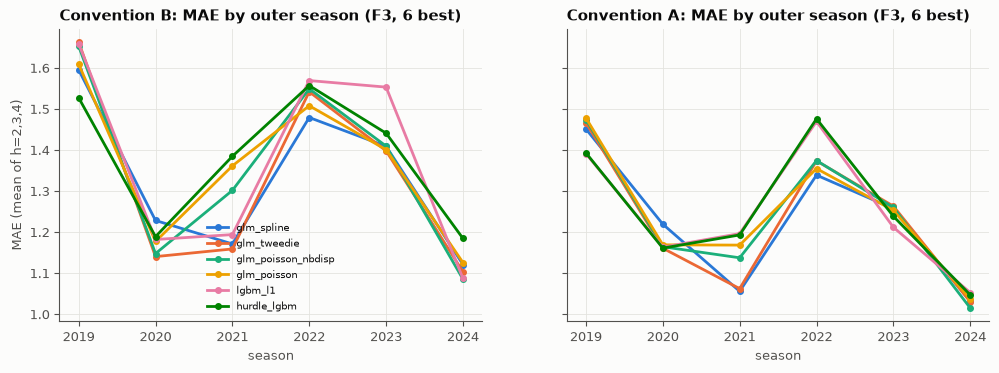

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for a, conv in zip(ax, ("B", "A")):
    s = scores[(scores.conv == conv) & (scores.fs == "F3") & scores.year.isin(S.OUTER)]
    yr = s.groupby(["model", "year"]).mae.mean().unstack("year")
    order = yr.mean(axis=1).sort_values().index
    for i, m in enumerate(order[:6]):
        a.plot(yr.columns, yr.loc[m], marker="o", ms=4, color=SERIES[i], label=m)
    a.set_title(f"Convention {conv}: MAE by outer season (F3, 6 best)"); a.set_xlabel("season")
ax[0].set_ylabel("MAE (mean of h=2,3,4)"); ax[0].legend(fontsize=7.5)
save(fig, "01_mae_by_season")

## 2. Bounded hyperparameter optimisation (Optuna, inner seasons 2019–2021, convention B, F3)

In [8]:
from dengueshield.optimization import search
# Runs (or resumes) the bounded plan: 20/20/15 trials, extended to 40 only if the GLM's inner MAE is beaten by >= 0.01.
# The first full run took 654 s (log of that run: optuna_run_log.json); re-running after completion does no new work.
plan_log = search.run_plan(panel, FS["F3"], "F3")
first = OUT / "optuna_run_log.json"
if not first.exists():
    first.write_text(json.dumps({**plan_log, "wall_seconds": plan_log["wall_seconds_this_call"]}, indent=2, default=float))
glm_obj, spl_obj = plan_log["glm_poisson_objective"], plan_log["glm_spline_objective"]
studies, trials = {}, []
for f in sorted((ROOT / ".cache/optuna").glob("*.db")):
    for summ in optuna.study.get_all_study_summaries(f"sqlite:///{f}"):
        st = optuna.load_study(study_name=summ.study_name, storage=f"sqlite:///{f}")
        model = summ.study_name.split("_F3")[0]
        studies[model] = st
        for t in st.trials:
            trials.append({"model": model, "number": t.number, "state": t.state.name, "value": t.value, "seconds": t.user_attrs.get("seconds"), **t.params})
trials = pd.DataFrame(trials); trials.to_csv(OUT / "optuna_trials.csv", index=False)
optlog = json.loads((OUT / "optuna_run_log.json").read_text())
summary = pd.DataFrame([{"model": m, "trials": len(st.trials), "complete": sum(t.state.name == "COMPLETE" for t in st.trials),
                         "pruned": sum(t.state.name == "PRUNED" for t in st.trials), "best_inner_mae": st.best_value,
                         "glm_inner_mae": glm_obj, "best_minus_glm": st.best_value - glm_obj} for m, st in studies.items()])
summary.to_csv(OUT / "optuna_summary.csv", index=False)
print(f"GLM inner objective {glm_obj:.4f}; spline GLM {spl_obj:.4f}; Optuna wall time {optlog['wall_seconds'] / 60:.1f} min")
summary.round(4)

[I 2026-11-21 16:46:00,568] Using an existing study with `study_name='lgbm_poisson_F3_B_tune2019-2021'` instead of creating a new one.


[I 2026-11-21 16:46:00,598] Using an existing study with `study_name='xgb_poisson_F3_B_tune2019-2021'` instead of creating a new one.


[I 2026-11-21 16:46:00,630] Using an existing study with `study_name='cat_poisson_F3_B_tune2019-2021'` instead of creating a new one.


[I 2026-11-21 16:46:00,654] Using an existing study with `study_name='lgbm_poisson_F3_B_tune2019-2021'` instead of creating a new one.


[I 2026-11-21 16:46:00,683] Using an existing study with `study_name='xgb_poisson_F3_B_tune2019-2021'` instead of creating a new one.


[I 2026-11-21 16:46:00,757] Using an existing study with `study_name='cat_poisson_F3_B_tune2019-2021'` instead of creating a new one.


GLM inner objective 1.3823; spline GLM 1.3313; Optuna wall time 10.9 min


,model,trials,complete,pruned,best_inner_mae,glm_inner_mae,best_minus_glm
0,cat_poisson,40,22,18,1.3495,1.3823,-0.0328
1,lgbm_poisson,40,21,19,1.3427,1.3823,-0.0396
2,xgb_poisson,40,26,14,1.3247,1.3823,-0.0576


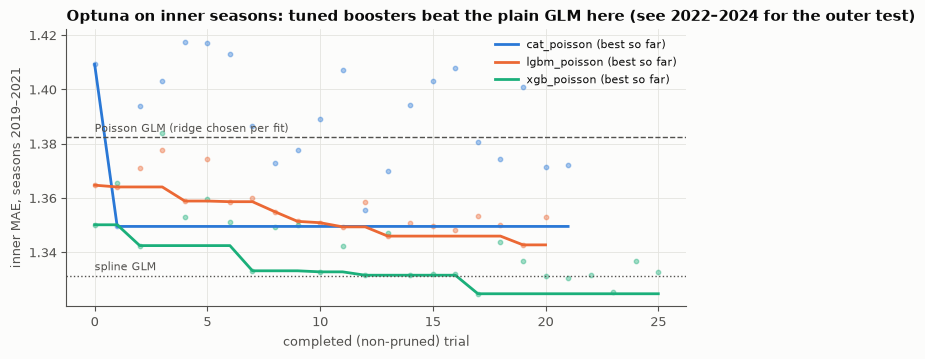

In [9]:
fig, ax = plt.subplots(figsize=(8, 3.6))
for i, (m, st) in enumerate(studies.items()):
    v = [t.value for t in st.trials if t.state.name == "COMPLETE"]
    ax.plot(range(len(v)), np.minimum.accumulate(v), color=SERIES[i], label=f"{m} (best so far)")
    ax.scatter(range(len(v)), v, s=10, color=SERIES[i], alpha=0.4)
ax.axhline(glm_obj, color=INK2, ls="--", lw=1); ax.text(0, glm_obj + 0.002, "Poisson GLM (ridge chosen per fit)", fontsize=8, color=INK2)
ax.axhline(spl_obj, color=INK2, ls=":", lw=1); ax.text(0, spl_obj + 0.002, "spline GLM", fontsize=8, color=INK2)
ax.set_xlabel("completed (non-pruned) trial"); ax.set_ylabel("inner MAE, seasons 2019–2021"); ax.legend(fontsize=8)
ax.set_title("Optuna on inner seasons: tuned boosters beat the plain GLM here (see 2022–2024 for the outer test)")
save(fig, "02_optuna_history")

Tuned models are refitted with their best inner parameters for every season and scored on **2022–2024 only** (nested).

In [10]:
tuned = []
for m, st in studies.items():
    prm = {**st.best_params, "early_stopping": True}
    tuned.append(T.run_grid(panel, [m], {"F3": FS["F3"]}, convs=("B", "A"), params={m: prm}, tag="tuned"))
tuned = pd.concat(tuned, ignore_index=True)
tuned_scores = S.score_table(tuned)

## 3. Nested ensembles (weights chosen on the two seasons before each outer year)

In [11]:
def P(model, conv, tag="", src=None):
    src = preds if src is None else src
    return src[(src.model == model) & (src.conv == conv) & (src.fs == "F3") & (src.tag == tag)].reset_index(drop=True)
ens_preds, ens_w = [], []
for conv in ("B", "A"):
    for a, b, name, src_b, tag_b in [("glm_poisson", "lgbm_poisson", "ens_glm+lgbm", None, ""), ("glm_poisson", "xgb_poisson", "ens_glm+xgb", None, ""),
                                     ("glm_poisson", "cat_poisson", "ens_glm+cat", None, ""), ("glm_poisson", "hurdle_lgbm", "ens_glm+hurdle", None, ""),
                                     ("glm_poisson", "glm_spline", "ens_glm+spline", None, ""), ("glm_poisson", "glm_tweedie", "ens_glm+tweedie", None, "")] + \
                                    [("glm_poisson", m, f"ens_glm+{m.split('_')[0]}_tuned", tuned, "tuned") for m in studies]:
        out, w = nested_blend(P(a, conv), P(b, conv, tag_b, src_b), name)
        out["conv"], out["fs"], out["tag"] = conv, "F3", "ensemble"
        ens_preds.append(out); ens_w.append(w.assign(conv=conv))
ens_preds, ens_w = pd.concat(ens_preds, ignore_index=True), pd.concat(ens_w, ignore_index=True)
ens_w.to_csv(OUT / "ensemble_weights.csv", index=False)
ens_scores = S.score_table(ens_preds)
display(ens_w[ens_w.conv == "B"].pivot_table(index="ensemble", columns="year", values="weight_A", aggfunc="mean").round(2))

year,2019,2020,2021,2022,2023,2024
ensemble,,,,,,
ens_glm+cat,0.80,0.60,0.57,0.60,0.57,0.83
ens_glm+cat_tuned,0.83,0.60,0.47,0.57,0.63,0.70
ens_glm+hurdle,0.87,0.63,0.40,0.70,0.70,0.73
ens_glm+lgbm,0.83,0.60,0.40,0.70,0.80,0.73
ens_glm+lgbm_tuned,0.83,0.63,0.37,0.53,0.63,0.70
ens_glm+spline,0.53,0.57,0.73,0.20,0.30,0.67
ens_glm+tweedie,0.23,0.23,0.37,0.13,0.00,0.03
ens_glm+xgb,0.80,0.57,0.43,0.63,0.77,0.70
ens_glm+xgb_tuned,0.80,0.57,0.30,0.50,0.60,0.53


## 4. Combined leaderboards (screen + tuned + ensembles)

In [12]:
allsc = pd.concat([scores, tuned_scores, ens_scores], ignore_index=True)
allsc.to_csv(OUT / "scores_all_cells.csv", index=False)
full = []
for conv in ("B", "A", "C"):
    for years, lab in ((S.OUTER, "outer_2019_2024"), (S.BENCH, "bench_2022_2024")):
        s = allsc[allsc.conv == conv]
        if lab.startswith("outer"):          # tuned models (and ensembles containing them) saw 2019-2021 during tuning
            s = s[(s.tag != "tuned") & ~s.model.str.endswith("_tuned")]
        lb = T.leaderboard(s, years).assign(convention=conv, years=lab)
        full.append(lb)
full = pd.concat(full, ignore_index=True); full.to_csv(OUT / "leaderboard_all.csv", index=False)
show = ["model", "fs", "tag", "mae_h2", "mae_h3", "mae_h4", "mae_avg", "year_sd", "rmse", "mae_mean", "high_mae", "high_bias", "recall", "precision", "false_alert_rate"]
print("CONVENTION B, 2022-2024 (all candidates incl. tuned and ensembles)")
display(full[(full.convention == "B") & (full.years == "bench_2022_2024")][show].round(3).head(20))

CONVENTION B, 2022-2024 (all candidates incl. tuned and ensembles)


,model,fs,tag,mae_h2,mae_h3,mae_h4,mae_avg,year_sd,rmse,mae_mean,high_mae,high_bias,recall,precision,false_alert_rate
28,glm_nb,F3,,1.095,1.385,1.486,1.322,0.217,2.654,1.365,4.780,-3.930,0.532,0.694,0.032
29,glm_nb,F8,,1.098,1.378,1.494,1.323,0.199,2.663,1.373,4.675,-3.599,0.566,0.683,0.036
30,ens_glm+spline,F3,ensemble,1.109,1.411,1.486,1.335,0.187,2.653,1.390,4.625,-3.626,0.567,0.690,0.035
31,glm_spline,F3,,1.113,1.409,1.486,1.336,0.190,2.653,1.392,4.634,-3.697,0.563,0.691,0.035
32,glm_poisson_nbdisp,F8,,1.109,1.394,1.508,1.337,0.204,2.684,1.401,4.828,-3.938,0.527,0.702,0.030
33,glm_poisson,F8,,1.107,1.393,1.512,1.337,0.161,2.667,1.401,4.564,-3.442,0.578,0.678,0.038
34,ens_glm+lgbm_tuned,F3,ensemble,1.106,1.397,1.513,1.339,0.176,2.669,1.391,4.604,-3.634,0.567,0.684,0.036
35,ens_glm+tweedie,F3,ensemble,1.108,1.377,1.534,1.340,0.174,2.672,1.390,4.650,-3.457,0.563,0.683,0.036
36,ens_glm+xgb_tuned,F3,ensemble,1.104,1.396,1.528,1.343,0.182,2.676,1.395,4.620,-3.689,0.569,0.676,0.037
37,glm_poisson,F3,,1.105,1.397,1.532,1.345,0.197,2.657,1.413,4.646,-3.646,0.567,0.691,0.034


In [13]:
print("CONVENTION B, 2019-2024 (untuned + ensembles; nested)")
display(full[(full.convention == "B") & (full.years == "outer_2019_2024")][show].round(3).head(15))
print("CONVENTION A, 2022-2024"); display(full[(full.convention == "A") & (full.years == "bench_2022_2024")][show].round(3).head(12))

CONVENTION B, 2019-2024 (untuned + ensembles; nested)


,model,fs,tag,mae_h2,mae_h3,mae_h4,mae_avg,year_sd,rmse,mae_mean,high_mae,high_bias,recall,precision,false_alert_rate
0,glm_spline,F8,,1.119,1.360,1.506,1.328,0.180,2.620,1.381,4.475,-3.530,0.559,0.635,0.040
1,glm_spline,F3,,1.123,1.377,1.502,1.334,0.189,2.627,1.395,4.593,-3.760,0.529,0.640,0.037
2,glm_tweedie,F3,,1.102,1.325,1.575,1.334,0.235,2.667,1.383,5.002,-4.214,0.459,0.644,0.028
3,ens_glm+tweedie,F3,ensemble,1.108,1.334,1.572,1.338,0.177,2.649,1.397,4.656,-3.605,0.524,0.643,0.038
4,ens_glm+spline,F3,ensemble,1.112,1.392,1.530,1.345,0.176,2.645,1.407,4.504,-3.515,0.553,0.641,0.040
5,ens_glm+xgb,F3,ensemble,1.105,1.392,1.553,1.350,0.178,2.665,1.409,4.534,-3.584,0.551,0.630,0.041
6,ens_glm+lgbm,F3,ensemble,1.112,1.388,1.550,1.350,0.171,2.665,1.413,4.526,-3.559,0.560,0.633,0.041
7,ens_glm+hurdle,F3,ensemble,1.106,1.389,1.559,1.352,0.177,2.668,1.414,4.536,-3.587,0.554,0.633,0.041
8,glm_poisson_nbdisp,F8,,1.112,1.377,1.571,1.353,0.194,2.681,1.426,4.641,-3.678,0.534,0.646,0.038
9,glm_poisson_nbdisp,F3,,1.112,1.372,1.588,1.357,0.223,2.685,1.440,4.869,-4.058,0.480,0.658,0.033


CONVENTION A, 2022-2024


,model,fs,tag,mae_h2,mae_h3,mae_h4,mae_avg,year_sd,rmse,mae_mean,high_mae,high_bias,recall,precision,false_alert_rate
90,glm_tweedie,F3,,1.077,1.129,1.421,1.209,0.159,2.408,1.247,4.313,-3.050,0.582,0.734,0.030
91,glm_poisson,F3,,1.075,1.136,1.432,1.214,0.163,2.399,1.263,4.199,-2.977,0.604,0.735,0.031
92,glm_nb,F3,,1.096,1.121,1.431,1.216,0.193,2.429,1.250,4.361,-3.459,0.570,0.751,0.027
93,glm_poisson_nbdisp,F3,,1.080,1.141,1.428,1.216,0.184,2.412,1.263,4.366,-3.325,0.568,0.749,0.027
94,ens_glm+lgbm,F3,ensemble,1.085,1.134,1.436,1.218,0.169,2.421,1.264,4.217,-2.996,0.602,0.726,0.032
95,ens_glm+tweedie,F3,ensemble,1.077,1.155,1.426,1.219,0.150,2.414,1.261,4.204,-2.763,0.613,0.720,0.034
96,ens_glm+xgb,F3,ensemble,1.087,1.133,1.440,1.220,0.177,2.430,1.265,4.210,-2.972,0.606,0.724,0.033
97,ens_glm+xgb_tuned,F3,ensemble,1.089,1.128,1.443,1.220,0.179,2.428,1.268,4.245,-3.114,0.601,0.730,0.031
98,ens_glm+lgbm_tuned,F3,ensemble,1.095,1.135,1.432,1.221,0.172,2.429,1.269,4.233,-3.057,0.597,0.729,0.031
99,ens_glm+cat_tuned,F3,ensemble,1.102,1.120,1.442,1.222,0.179,2.426,1.270,4.252,-3.161,0.596,0.728,0.032


In [14]:
pb = T.paired(allsc[allsc.conv == "B"], {"model": "glm_poisson", "fs": "F3", "conv": "B", "tag": ""}, S.BENCH)
po = T.paired(allsc[(allsc.conv == "B") & (allsc.tag != "tuned") & ~allsc.model.str.endswith("_tuned")], {"model": "glm_poisson", "fs": "F3", "conv": "B", "tag": ""}, S.OUTER)
pb.to_csv(OUT / "paired_all_vs_glm_B_bench.csv", index=False); po.to_csv(OUT / "paired_all_vs_glm_B_outer.csv", index=False)
display(po.head(10).round(3)); pb.head(10).round(3)

,model,fs,conv,tag,mean_diff,cells_better,cells,years_better,years,ci95_lo,ci95_hi
15,glm_spline,F8,B,,-0.035,10,18,4,6,-0.111,0.041
14,glm_spline,F3,B,,-0.030,9,18,4,6,-0.117,0.058
16,glm_tweedie,F3,B,,-0.029,13,18,4,6,-0.125,0.066
6,ens_glm+tweedie,F3,B,ensemble,-0.025,12,18,5,6,-0.071,0.021
5,ens_glm+spline,F3,B,ensemble,-0.019,8,18,4,6,-0.054,0.016
7,ens_glm+xgb,F3,B,ensemble,-0.013,7,18,4,6,-0.038,0.011
4,ens_glm+lgbm,F3,B,ensemble,-0.013,7,18,4,6,-0.039,0.012
3,ens_glm+hurdle,F3,B,ensemble,-0.012,9,18,4,6,-0.045,0.021
13,glm_poisson_nbdisp,F8,B,,-0.010,12,18,5,6,-0.022,0.002
12,glm_poisson_nbdisp,F3,B,,-0.006,10,18,3,6,-0.052,0.040


,model,fs,conv,tag,mean_diff,cells_better,cells,years_better,years,ci95_lo,ci95_hi
12,glm_nb,F3,B,,-0.023,7,9,2,3,-0.086,0.041
13,glm_nb,F8,B,,-0.022,8,9,3,3,-0.034,-0.010
8,ens_glm+spline,F3,B,ensemble,-0.009,3,9,2,3,-0.061,0.043
18,glm_spline,F3,B,,-0.008,5,9,2,3,-0.055,0.038
17,glm_poisson_nbdisp,F8,B,,-0.008,6,9,2,3,-0.034,0.019
15,glm_poisson,F8,B,,-0.007,4,9,2,3,-0.098,0.083
7,ens_glm+lgbm_tuned,F3,B,ensemble,-0.006,3,9,1,3,-0.097,0.085
9,ens_glm+tweedie,F3,B,ensemble,-0.005,4,9,2,3,-0.064,0.054
11,ens_glm+xgb_tuned,F3,B,ensemble,-0.002,4,9,1,3,-0.077,0.073
14,glm_poisson,F3,B,,0.000,0,9,0,3,0.000,0.000


## 5. Convention C (one-week case reporting delay) and convention comparison

In [15]:
cc = allsc[(allsc.fs == "F3") & (allsc.tag == "") & allsc.model.isin(["glm_poisson", "glm_tweedie", "lgbm_poisson", "xgb_poisson", "cat_poisson"])]
cv = cc[cc.year.isin(S.OUTER)].groupby(["model", "conv"]).mae.mean().unstack("conv").round(3)
cv["B_minus_A"], cv["C_minus_A"] = cv.B - cv.A, cv.C - cv.A
cv.to_csv(OUT / "convention_comparison_outer.csv"); cv

conv,A,B,C,B_minus_A,C_minus_A
model,,,,,
cat_poisson,1.272,1.407,1.278,0.135,0.006
glm_poisson,1.243,1.363,1.243,0.120,0.000
glm_tweedie,1.225,1.334,1.225,0.109,0.000
lgbm_poisson,1.247,1.389,1.250,0.142,0.003
xgb_poisson,1.264,1.382,1.257,0.118,-0.007


## 6. Stage 2 → Stage 3 comparison and champion selection

**Champion rule (fixed before the tuned and ensemble results were inspected):**
1. *Eligible*: nested-valid under convention B on 2022–2024, no failed fits, and a predictive distribution (needed for intervals).
2. *Shortlist*: within **0.05 MAE** of the best eligible average MAE (convention B, 2022–2024; the only window in which every candidate,
   including tuned ones, is nested).
3. *Pick* the simplest shortlisted model (plain Poisson GLM < other GLM variants < ensembles < boosting), then fewer features, then lower MAE;
   it must also be within 0.05 of the best on the longer 2019–2024 window (robustness).
4. *Per-horizon override* only if another eligible candidate beats the pick by ≥ 0.05 at that horizon on **both** windows.

In [16]:
FAILED = {"glm_nb": "unpenalised NB IRLS diverged in short-history seasons (season MAE 2.47 in 2018, 1.95 in 2019)",
          "lgbm_l1": "point forecast only (no predictive distribution, so no intervals or expected cases)"}
def complexity(model, tag):
    if model == "glm_poisson": return 1
    if model.startswith("glm_"): return 2
    if model.startswith("ens_"): return 3
    return 4
cb = full[(full.convention == "B") & (full.years == "bench_2022_2024") & ~full.model.isin(list(FAILED))].copy()
co = full[(full.convention == "B") & (full.years == "outer_2019_2024")].set_index(["model", "fs", "tag"])
cb["outer_mae_avg"] = [co.mae_avg.get((r.model, r.fs, r.tag), np.nan) for r in cb.itertuples()]
cb["complexity"] = [complexity(r.model, r.tag) for r in cb.itertuples()]
cb["n_features"] = cb.fs.map({k: len(v) for k, v in FS.items()})
best_b, best_o = cb.mae_avg.min(), cb.outer_mae_avg.min()
short = cb[(cb.mae_avg <= best_b + 0.05) & ((cb.outer_mae_avg <= best_o + 0.05) | cb.outer_mae_avg.isna())]
short = short.sort_values(["complexity", "n_features", "mae_avg"])
pick = short.iloc[0]
assert not pick.model.startswith("ens_"), "an ensemble champion would need a two-model bundle (not implemented)"
over = {}
for h in (2, 3, 4):
    hb = cb.set_index(["model", "fs", "tag"])[f"mae_h{h}"]
    ho = co[f"mae_h{h}"]
    pk = (pick.model, pick.fs, pick.tag)
    better = [(k, hb[pk] - hb[k], ho.get(pk, np.nan) - ho.get(k, np.nan)) for k in hb.index if hb[pk] - hb[k] >= 0.05 and ho.get(pk, np.nan) - ho.get(k, np.nan) >= 0.05]
    over[h] = max(better, key=lambda x: x[1])[0] if better else (pick.model, pick.fs, pick.tag)
display(short[["model", "fs", "tag", "complexity", "n_features", "mae_h2", "mae_h3", "mae_h4", "mae_avg", "outer_mae_avg", "year_sd", "high_mae", "recall", "precision"]].round(3))
print("best bench", round(best_b, 4), "| best outer", round(best_o, 4), "| pick:", pick.model, pick.fs, pick.tag, "| per-horizon:", over)

,model,fs,tag,complexity,n_features,mae_h2,mae_h3,mae_h4,mae_avg,outer_mae_avg,year_sd,high_mae,recall,precision
33,glm_poisson,F8,,1,24,1.107,1.393,1.512,1.337,1.365,0.161,4.564,0.578,0.678
37,glm_poisson,F3,,1,38,1.105,1.397,1.532,1.345,1.363,0.197,4.646,0.567,0.691
32,glm_poisson_nbdisp,F8,,2,24,1.109,1.394,1.508,1.337,1.353,0.204,4.828,0.527,0.702
39,glm_spline,F8,,2,24,1.119,1.406,1.510,1.345,1.328,0.174,4.640,0.566,0.680
31,glm_spline,F3,,2,38,1.113,1.409,1.486,1.336,1.334,0.190,4.634,0.563,0.691
42,glm_tweedie,F3,,2,38,1.099,1.377,1.566,1.347,1.334,0.223,4.958,0.506,0.697
43,glm_poisson_nbdisp,F3,,2,38,1.108,1.397,1.538,1.348,1.357,0.238,4.956,0.500,0.715
30,ens_glm+spline,F3,ensemble,3,38,1.109,1.411,1.486,1.335,1.345,0.187,4.625,0.567,0.690
34,ens_glm+lgbm_tuned,F3,ensemble,3,38,1.106,1.397,1.513,1.339,NaN,0.176,4.604,0.567,0.684
35,ens_glm+tweedie,F3,ensemble,3,38,1.108,1.377,1.534,1.340,1.338,0.174,4.650,0.563,0.683


best bench 1.3353 | best outer 1.3283 | pick: glm_poisson F8  | per-horizon: {2: ('glm_poisson', 'F8', ''), 3: ('glm_poisson', 'F8', ''), 4: ('glm_poisson', 'F8', '')}


In [17]:
def vrow(model, conv, years, fs, tag=""):
    s = allsc[(allsc.model == model) & (allsc.conv == conv) & (allsc.fs == fs) & (allsc.tag == tag) & allsc.year.isin(years)]
    return s.groupby("horizon")[["mae", "rmse", "mae_mean", "rmse_mean", "high_mae", "high_bias", "recall", "precision", "false_alert_rate"]].mean()
champ = {"convention_primary": "B_start_of_week", "rule": "see notebook 07 section 6", "failed_models": FAILED,
         "per_horizon": {str(h): {"model": over[h][0], "fs": over[h][1], "tag": over[h][2],
                                  "params": ({**studies[over[h][0]].best_params, "early_stopping": True} if over[h][2] == "tuned" else {})} for h in (2, 3, 4)},
         "best_scoring_alternative_B_bench": cb.sort_values("mae_avg").iloc[0][["model", "fs", "tag", "mae_avg"]].to_dict(),
         "validation": {}}
for conv in ("B", "A"):
    v = {}
    for h in (2, 3, 4):
        c = champ["per_horizon"][str(h)]
        b = vrow(c["model"], conv, S.BENCH, c["fs"], c["tag"]).loc[h].round(4).to_dict()
        o = vrow(c["model"], conv, S.OUTER, c["fs"], c["tag"]).loc[h].round(4).to_dict()
        v[str(h)] = {"bench_2022_2024": b, "outer_2019_2024": o}
    champ["validation"][conv] = v
(OUT / "champion.json").write_text(json.dumps(champ, indent=1, default=float))
print(json.dumps(champ["per_horizon"], indent=1))

{
 "2": {
  "model": "glm_poisson",
  "fs": "F8",
  "tag": "",
  "params": {}
 },
 "3": {
  "model": "glm_poisson",
  "fs": "F8",
  "tag": "",
  "params": {}
 },
 "4": {
  "model": "glm_poisson",
  "fs": "F8",
  "tag": "",
  "params": {}
 }
}


In [18]:
# Stage 2 -> Stage 3: same convention, same years. Stage 2 champion = Poisson GLM, F3 (regime rain projection in Stage 2; clim here).
stage2_A = {2: 1.075, 3: 1.137, 4: 1.437}; stage2_B_avg = 1.341
rows = []
for conv in ("B", "A"):
    for h in (2, 3, 4):
        c = champ["per_horizon"][str(h)]
        ch = vrow(c["model"], conv, S.BENCH, c["fs"], c["tag"]).loc[h]
        s2 = vrow("glm_poisson", conv, S.BENCH, "F3").loc[h]
        rows.append({"convention": conv, "horizon": h, "stage2_glm_F3_mae": s2.mae, "stage3_champion_mae": ch.mae,
                     "mae_change_pct": 100 * (ch.mae - s2.mae) / s2.mae, "stage2_rmse": s2.rmse, "stage3_rmse": ch.rmse,
                     "stage2_high_mae": s2.high_mae, "stage3_high_mae": ch.high_mae, "stage2_recall": s2.recall, "stage3_recall": ch.recall,
                     "stage1_benchmark_A": {2: 1.094, 3: 1.213, 4: 1.517}[h] if conv == "A" else np.nan})
s23 = pd.DataFrame(rows); s23.round(4).to_csv(OUT / "stage2_vs_stage3.csv", index=False); s23.round(3)

,convention,horizon,stage2_glm_F3_mae,stage3_champion_mae,mae_change_pct,stage2_rmse,stage3_rmse,stage2_high_mae,stage3_high_mae,stage2_recall,stage3_recall,stage1_benchmark_A
0,B,2,1.105,1.107,0.219,2.202,2.220,3.920,3.934,0.626,0.624,NaN
1,B,3,1.397,1.393,-0.326,2.781,2.794,4.863,4.864,0.564,0.552,NaN
2,B,4,1.532,1.512,-1.267,2.988,2.988,5.155,4.895,0.511,0.557,NaN
3,A,2,1.075,1.069,-0.596,2.146,2.124,3.907,3.812,0.620,0.628,1.094
4,A,3,1.136,1.152,1.411,2.222,2.277,3.856,3.968,0.626,0.621,1.213
5,A,4,1.432,1.459,1.844,2.828,2.876,4.835,4.977,0.565,0.536,1.517
